# Induction heads: do they carry the in-context grammar learning?

**Question.** A frozen Mistral-7B learns the AGL and SRTT grammars from its prompt alone, and the learning becomes
readable abruptly at **layer 19** (`01_logit_lens`, `02_tuned_lens`). Is it carried by **induction heads**
(Olsson et al., 2022)? An induction head implements *[A][B] … [A] → [B]*: at the current token it attends to the
token that came right after the previous occurrence of the same token, and copies it. Hypothesis: induction heads
sit around layers 13–19, and switching them off destroys SRTT learning (pure copying of a fixed sequence) and
reduces AGL learning partly or fully.

**Plan.**
1. **Find induction heads** (minutes): score all 32 × 32 = 1,024 attention heads on two properties: do they look
   at "the token after the previous copy of me" (prefix matching), and do they push up the word they look at
   (copying)?
2. **Switch them off** (ablation) and rerun the grammar streams: top-k induction heads for k = 4, 8, 16, 32, versus
   the same number of random non-induction heads from the same layers.
3. **Check general damage** on Wikipedia text, so that a drop in grammar learning is not just a broken model.
4. **Measure**: learning curves, a dose-response summary, the per-state check for AGL, and the per-layer logit
   lens for the baseline and the largest ablation.

**Run order and time (Colab T4, 8-bit model).** Run all cells top to bottom. Step 1 takes a few minutes. Step 2
runs one condition at a time and saves each finished condition (and every 10 runs within it) to Google Drive, so
after a disconnect: reconnect, **Runtime → Run all**, approve the Drive popup, and finished conditions load in
seconds. The runtime-estimate cell prints the expected total before the long part starts (about 4–5 hours with
the defaults, `N_RUNS = 50`, spread over as many sessions as needed).

## ⚠️ Correction note for this run (run 1)

This is the first full run (Colab T4, 8-bit model, 50 runs per grammar), kept exactly as it ran. One part of it is
flawed, and the corrected notebooks are `induction_heads.ipynb` (full) and `induction_heads_short.ipynb` (rerun).

**The copying score was wrong.** It measured the share of all the logit mass a head raises that goes to the attended
token. Spread over ~32k tokens, that share is ~0.000–0.001 for every head, so no head passed the copying threshold,
and ranking heads by prefix × copying was close to arbitrary. The corrected score is rank-based: where the attended
token ranks among all tokens in the head's direct-path output, scaled to −1…+1 (0 = chance).

**What was actually ablated.** The "top-k" sets below were ordered by that noisy ranking. The top 32 included the
three strongest induction heads (block 18, heads 0, 2, 3; prefix ≈ 0.9) plus 29 weak ones (prefix 0.1–0.3), and
missed the strong heads in block 12 (heads 6, 7; prefix ≈ 0.9) and block 28 head 0. The results below therefore
mostly reflect the block-18 induction heads.

**Layer numbering.** The head heatmaps index heads by transformer block (0–31). The logit lens's "layer N" is the
state *after* block N−1, so block 12 writes into lens layer 13 (the small step) and block 18 into lens layer 19 (the
jump). The dashed lines on the head heatmaps in this run are drawn at 13 and 19; they should be at 12 and 18.

**Main results of this run (still valid as an experiment on the heads that were ablated):**
- 32 random layer-matched heads: no effect (AGL 0.73–0.74 vs. 0.745; SRTT ≈ 0.997).
- The top-32 set (with the block-18 induction heads): AGL learning 0.745 → 0.405, SRTT 0.997 → 0.872; Wikipedia loss
  +1.4% (random: +0.5%); Olsson's ICL score on Wikipedia unchanged. Zero ablation ≈ mean ablation.
- Per-layer lens: the jump at lens layer 19 halves (AGL 0.41 → 0.19, SRTT 0.51 → 0.25); layers 0–18 unchanged;
  later layers recover part of it (SRTT almost fully by layer 32).
- AGL state q1: allowed vs. forbidden continuations still separate (0.26 vs. 0.035; baseline 0.30 vs. 0.03).


In [1]:
# Stop right away if there is no GPU (NVIDIA in Colab, or an Apple Silicon Mac): on CPU the 7B model does not
# fit in memory and loading stalls.
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # less memory fragmentation
import torch
REQUIRE_GPU = True
if torch.cuda.is_available():
  print(f"GPU: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
  print("GPU: Apple Silicon (MPS); the model runs in float16 (8-bit loading needs an NVIDIA GPU)")
elif REQUIRE_GPU:
  raise RuntimeError("No GPU. In Colab: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all. "
                     "If Colab says no GPU is available, its free GPU quota is used up for now: try again later.")

# Google Drive first: Colab asks for permission once per new runtime. Approve the popup right away;
# "Run all" waits here until you do. Everything slow (tuned lens, lens results) is saved there.
USE_GOOGLE_DRIVE = True
DRIVE_CACHE_DIR = '/content/drive/MyDrive/plasticity_lens_cache'
if USE_GOOGLE_DRIVE:
  try:
    from google.colab import drive
    drive.mount('/content/drive')
  except ImportError:
    print("not running in Colab; results are saved locally")

!pip install -q -U bitsandbytes
!pip install -q datasets  # tuned-lens training text


GPU: Tesla T4
Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 19.2 MB/s eta 0:00:00


## Import packages

In [2]:
import json
import random
from tqdm import tqdm
random.seed(42)

## Set run parameters

In [3]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
LOAD_IN_8BIT_ON_CUDA = True  # set False if your GPU has enough memory for full float16 (e.g. A100/L4); needed on a free-tier T4 (14.5GB) to avoid OOM
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [4]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    import spacy  # only needed for tokens_type "all_nouns"/"all_verbs" (requires en_core_web_trf)
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [5]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'air

In [6]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

## Generate Sequences

In [7]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [8]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [9]:
def build_random_DFA(vocab):
  vocab_copy = vocab.copy()
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [10]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [11]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [12]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### AGL word streams

In [13]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

100%|██████████| 100/100 [00:00<00:00, 181.74it/s]


In [14]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]  # same as meeting 1

output = {"shuffle": []}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  output["shuffle"].append(prompt_dict.copy())
  output["shuffle"][-1]["mapped_prompt"] = map_prompt(prompt_dict["placeholder_prompt"], shuffle_vocab[i])
  output["shuffle"][-1]["vocab"] = shuffle_vocab[i]


### SRTT word streams

In [15]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [16]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [17]:
# NOTE: all SRTT runs share ONE generated sequence (including the random baseline/post segments);
# only the vocabulary differs between runs, so averaging over runs averages over vocabularies,
# not over random sequences. (The SRTT cells below also assume equal-length runs.)
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]


In [18]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

## Load the model

In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [20]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [21]:
import logging
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)  # silences repeated per-matmul cast-precision
                                                              # logging noise from the 8-bit quantized model;
                                                              # purely cosmetic, no effect on results

In [22]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  if device == 'cuda' and LOAD_IN_8BIT_ON_CUDA:
    from transformers import BitsAndBytesConfig
    quantization_config = BitsAndBytesConfig(load_in_8bit=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, quantization_config=quantization_config, low_cpu_mem_usage=True)
  else:
    dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [24]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


device: cuda
loading mistral...


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/137k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

LOADING DONE!
Model: mistralai/Mistral-7B-v0.3
Context window length: 32768
Number of parameters: 7,248,023,552
Hugging Face URL: https://huggingface.co/mistralai/Mistral-7B-v0.3


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14})


## Shared tools from the lens notebooks

The next cells are copied unchanged from `02_tuned_lens`: settings and Google Drive caching, the logit lens
(`get_layer_logits`), the per-run extraction with saving and resuming (`run_lens_extraction`), the per-layer
summary (`lens_phase_summary`), the plotting helpers, and the Wikipedia text loader (`load_lens_training_tokens`).
The tuned lens itself is not used here.

In [26]:
import os

LAYERS_TO_DECODE = 'all'  # 'all' decodes every layer (0 = embedding output, 1..32 = after each transformer block);
                          # or set a list like [0, 8, 16, 24, 32] for a lighter run
LENS_CACHE_DIR = 'lens_cache'  # per-condition results are pickled here and reloaded if the inputs match;
                               # point it at a mounted Google Drive folder to survive a Colab reconnect. None = off
LAST_N_STRUCTURED = 1000  # summary window: last (and first) N tokens of the structured phase
BASELINE_WARMUP = 50  # skip the first N baseline tokens (the model has not seen the alphabet yet; full-vocab P climbs from ~0)

# Tuned lens (trained once on generic text, never on the grammar task; see "Tuned lens" below)
TUNED_LENS_DATASET = ("Salesforce/wikitext", "wikitext-103-raw-v1")  # (HF dataset, config), streamed
TUNED_LENS_STEPS = 400        # optimizer steps (~40 min on a T4)
TUNED_LENS_BATCH = 2          # sequences per step (2 x 512 fits a 15 GB T4 next to the 8-bit model)
TUNED_LENS_SEQ_LEN = 512      # tokens per sequence (BOS + 511)
TUNED_LENS_POSITIONS_PER_SEQ = 128  # train on a random subset of positions per sequence: the lens (not the model)
                                    # is most of the cost per position, and neighbouring positions are redundant
TUNED_LENS_LR = 1.0           # SGD with Nesterov momentum, linear decay to 0 (as in Belrose et al. 2023)
TUNED_LENS_MOMENTUM = 0.9
TUNED_LENS_WEIGHT_DECAY = 1e-3
TUNED_LENS_VAL_SEQS = 16      # held-out sequences (validation split) for the lens-quality check
TUNED_LENS_CHECKPOINT_EVERY = 50  # save training progress every N steps (~5 min on a T4) and resume from it
LENS_RUNS_PER_SAVE = 10  # lens passes save their progress every N runs and resume from there

if USE_GOOGLE_DRIVE and os.path.isdir('/content/drive/MyDrive'):
  LENS_CACHE_DIR = DRIVE_CACHE_DIR
print(f"saving the tuned lens and lens results to: {LENS_CACHE_DIR}")


def lens_cache_name(grammar):
  """Cache key includes everything that changes the numbers for the same input tokens."""
  quant = '8bit' if (get_device() == 'cuda' and LOAD_IN_8BIT_ON_CUDA) else ('fp16' if get_device() in ('cuda', 'mps') else 'fp32')
  return f"{grammar}_{model_name}_{'rand' if RANDOM_WEIGHTS else 'trained'}_{quant}"


saving the tuned lens and lens results to: /content/drive/MyDrive/plasticity_lens_cache


In [27]:
def get_layer_logits(model, hidden_state, is_last):
  """Logit lens: applies the model's own final norm + LM head to one layer's hidden state.
  hidden_states[-1] has already been through model.model.norm in HF Mistral/Llama, so the
  last layer goes straight to lm_head (norming it twice changes its direction). Returns float32."""
  if model_name not in ('mistral', 'llama'):
    raise NotImplementedError(
      f"get_layer_logits only supports mistral/llama-style architectures (model.model.norm + "
      f"model.lm_head), got model_name={model_name!r}"
    )
  with torch.no_grad():
    h = hidden_state if is_last else model.model.norm(hidden_state)
    return model.lm_head(h).float()


class TunedLens(torch.nn.Module):
  """One affine "translator" per layer (Belrose et al. 2023): h -> h + W h + b, initialized to zero
  (i.e. starting exactly at the logit lens). The last layer has no translator: it is the model's output."""
  def __init__(self, num_layers, hidden_size):
    super().__init__()
    self.translators = torch.nn.ModuleList(torch.nn.Linear(hidden_size, hidden_size) for _ in range(num_layers))
    for translator in self.translators:
      torch.nn.init.zeros_(translator.weight)
      torch.nn.init.zeros_(translator.bias)


def tuned_lens_logits(model, tuned_lens, hidden_state, layer_idx):
  """Tuned lens for a layer below the last: translator (float32) -> the model's final norm -> lm_head.
  No torch.no_grad here: training backpropagates through it into the translator. Returns float32.
  The translators may live on the CPU (to leave GPU memory for the forward pass); the one needed is
  copied to the GPU per call (64 MB). During training they live on the GPU and nothing is copied."""
  h = hidden_state.float()
  translator = tuned_lens.translators[layer_idx]
  h = h + torch.nn.functional.linear(h, translator.weight.to(h.device), translator.bias.to(h.device))
  normed = model.model.norm(h)
  return model.lm_head(normed.to(model.lm_head.weight.dtype)).float()


In [28]:
import os
import pickle
from scipy.special import logsumexp


def prepare_lens_inputs(tokenizer, prompt_dict):
  """Tokenizes one run exactly like calculate_next_token_probs (each word reduced to its first
  subword, BOS prepended) and returns the candidate token ids plus, for every prompt position t,
  the candidate column of the token that actually comes next. Reads prompt_dict, never writes it.
  Works whether or not get_next_token_probabilities already rewrote mapped_prompt/vocab in place."""
  vocab = prompt_dict["vocab"]
  if type(vocab[0]) == list:
    vocab = [item for sublist in vocab for item in sublist]
  words = [w for w in vocab if w != SEP_TOKEN]  # vocab may already contain SEP_TOKEN (in-place mutation)
  first_token_id = {w: tokenizer.encode(w, return_tensors='pt')[0, 1].item() for w in words + [SEP_TOKEN]}
  one_token_mapping = {w: tokenizer.decode(first_token_id[w]) for w in words}
  one_token_mapping[SEP_TOKEN] = SEP_TOKEN
  input_sequence = [one_token_mapping[w] for w in prompt_dict["mapped_prompt"]]
  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)

  # De-duplicated candidate ids: words first (vocab order), END last. Two words that share a first
  # subword collapse into one column, as they already do in the final-layer pipeline.
  cand_ids = list(dict.fromkeys([first_token_id[w] for w in words] + [first_token_id[SEP_TOKEN]]))
  col_of = {tid: c for c, tid in enumerate(cand_ids)}
  next_ids = input_ids[0, 1:].tolist()
  assert len(next_ids) == len(prompt_dict["mapped_prompt"]), "every word must map to exactly one token"
  assert all(t in col_of for t in next_ids), "input token missing from the candidate set"
  target_col = np.array([col_of[t] for t in next_ids], dtype=np.int64)
  return {"input_ids": input_ids, "cand_ids": cand_ids, "target_col": target_col,
          "num_words": len(words)}


def extract_lens_logprobs(model, lens_inputs, layers_to_decode='all', report_double_norm=False, tuned_lens=None):
  """One forward pass with output_hidden_states=True. For every requested layer, stores the
  full-vocab log-probabilities (float32) of the candidate tokens only: shape (layers, N, C),
  row t = prediction for prompt token t (the BOS shift is handled by dropping the last row).
  Checks that the lens on the last hidden state reproduces outputs.logits.
  Returns {"logit": result} or, with tuned_lens, {"logit": result, "tuned": result} from the same pass."""
  device = get_device()
  input_ids = lens_inputs["input_ids"].to(device)
  cand = torch.tensor(lens_inputs["cand_ids"], device=device)
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    hidden_states = outputs.hidden_states  # (embeddings, after layer 1, ..., after layer N [already normed])
    num_layers = len(hidden_states) - 1
    layer_indices = list(range(num_layers + 1)) if layers_to_decode == 'all' else list(layers_to_decode)

    # Sanity check (every run, cheap): lens on the last layer == the model's real output.
    last_logits = get_layer_logits(model, hidden_states[-1][0, :-1], is_last=True)
    real_logits = outputs.logits[0, :-1].float()
    last_layer_max_abs_diff = (last_logits - real_logits).abs().max().item()
    assert last_layer_max_abs_diff < 1e-2, f"lens on last layer != outputs.logits (max |diff| = {last_layer_max_abs_diff})"
    if report_double_norm:
      double = model.lm_head(model.model.norm(hidden_states[-1][0, :-1])).float()
      print(f"[sanity] last layer, lens vs outputs.logits: max|diff| = {last_layer_max_abs_diff:.2e}; "
            f"old double-norm lens vs outputs.logits: max|diff| = {(double - real_logits).abs().max().item():.2e}")
      del double
    del real_logits

    lens_names = ["logit"] + (["tuned"] if tuned_lens is not None else [])
    per_layer = {name: [] for name in lens_names}
    for layer_idx in layer_indices:
      is_last = layer_idx == num_layers
      for name in lens_names:
        if is_last:  # both lenses read the last layer as the model's real output
          logits = last_logits
        elif name == "logit":
          logits = get_layer_logits(model, hidden_states[layer_idx][0, :-1], is_last=False)
        else:
          logits = tuned_lens_logits(model, tuned_lens, hidden_states[layer_idx][0, :-1], layer_idx)
        cand_logprobs = logits[:, cand] - torch.logsumexp(logits, dim=-1, keepdim=True)
        per_layer[name].append(cand_logprobs.cpu().numpy().astype(np.float32))
        del cand_logprobs
        if not is_last:
          del logits
    del outputs, hidden_states, last_logits

  common = {"layers": layer_indices, "target_col": lens_inputs["target_col"], "cand_ids": lens_inputs["cand_ids"],
            "input_ids": lens_inputs["input_ids"][0].numpy().astype(np.int32),
            "last_layer_max_abs_diff": last_layer_max_abs_diff}
  return {name: dict(common, logprobs=np.stack(v)) for name, v in per_layer.items()}  # logprobs: (L, N, C) float32


def run_lens_extraction(model, tokenizer, all_prompts, layers_to_decode='all', cache_name=None, tuned_lens=None):
  """Runs extract_lens_logprobs on every run. Tokenizes (and validates) all runs before the first
  forward pass, so an input problem fails in seconds rather than minutes in. Returns
  {"logit": [one result per run]} (plus "tuned" with tuned_lens), all from one forward pass per run;
  the prompt dicts are not modified."""
  all_inputs = [prepare_lens_inputs(tokenizer, p) for p in all_prompts]
  for inp, p in zip(all_inputs, all_prompts):  # only if a final-layer pass (get_probabilities) was run on these dicts
    if "token_ids_sequence" in p:
      assert set(inp["cand_ids"]) == set(p["token_ids_sequence"]), "lens tokenization != final-layer pass"
  n_collapsed = sum(len(inp["cand_ids"]) < inp["num_words"] + 1 for inp in all_inputs)
  if n_collapsed:
    print(f"warning: {n_collapsed} run(s) have two words sharing a first subword (fewer than "
          f"{all_inputs[0]['num_words'] + 1} candidate columns)")

  cache_path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if (LENS_CACHE_DIR and cache_name) else None
  if cache_path and os.path.exists(cache_path):
    with open(cache_path, 'rb') as f:
      cached = pickle.load(f)
    expected_layers = None if layers_to_decode == 'all' else list(layers_to_decode)
    if (set(cached) == ({"logit", "tuned"} if tuned_lens is not None else {"logit"})
        and len(cached["logit"]) == len(all_inputs)
        and all(np.array_equal(c["input_ids"], inp["input_ids"][0].numpy()) for c, inp in zip(cached["logit"], all_inputs))
        and (expected_layers is None or cached["logit"][0]["layers"] == expected_layers)):
      print(f"loaded {len(cached['logit'])} runs ({' + '.join(cached)} lens) from {cache_path}")
      return cached
    print(f"cache {cache_path} does not match the current inputs; recomputing")

  device = get_device()
  per_run = []
  part_path = lambda k: f"{cache_path}.part{k:03d}"  # one file per LENS_RUNS_PER_SAVE runs
  if cache_path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    k = 0
    while os.path.exists(part_path(k)):
      with open(part_path(k), 'rb') as f:
        part = pickle.load(f)
      start = len(per_run)
      if not all(np.array_equal(r["logit"]["input_ids"], inp["input_ids"][0].numpy())
                 for r, inp in zip(part, all_inputs[start:start + len(part)])) or set(part[0]) != set(
                   ["logit"] + (["tuned"] if tuned_lens is not None else [])):
        print(f"saved partial results {part_path(k)} do not match the current inputs; recomputing from run {start}")
        break
      per_run.extend(part)
      k += 1
    if per_run:
      print(f"resuming the lens pass at run {len(per_run)}/{len(all_inputs)} (saved partial results)")

  for idx in tqdm(range(len(per_run), len(all_inputs)), initial=len(per_run), total=len(all_inputs)):
    per_run.append(extract_lens_logprobs(model, all_inputs[idx], layers_to_decode, report_double_norm=(idx == 0),
                                         tuned_lens=tuned_lens))
    if cache_path and (idx + 1) % LENS_RUNS_PER_SAVE == 0:
      part = per_run[idx + 1 - LENS_RUNS_PER_SAVE:idx + 1]
      tmp = part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1) + ".tmp"
      with open(tmp, 'wb') as f:
        pickle.dump(part, f)
      os.replace(tmp, part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1))
    if idx % 10 == 0:
      if device == 'cuda':
        torch.cuda.empty_cache()
      elif device == 'mps':
        torch.mps.empty_cache()
  results = {name: [r[name] for r in per_run] for name in per_run[0]}
  print(f"max |lens(last layer) - outputs.logits| over runs: {max(r['last_layer_max_abs_diff'] for r in results['logit']):.2e}")

  if cache_path:
    with open(cache_path + ".tmp", 'wb') as f:
      pickle.dump(results, f)
    os.replace(cache_path + ".tmp", cache_path)
    k = 0
    while os.path.exists(part_path(k)):
      os.remove(part_path(k))
      k += 1
  return results


In [29]:
def lens_next_token_probs(lens_result, renormalize):
  """(L, N) probability of the actual next token at every layer and prompt position.
  renormalize=False: full-vocab softmax. True: softmax restricted to the candidate tokens."""
  logprobs = lens_result["logprobs"].astype(np.float64)
  if renormalize:
    logprobs = logprobs - logsumexp(logprobs, axis=-1, keepdims=True)
  n = logprobs.shape[1]
  return np.exp(logprobs[:, np.arange(n), lens_result["target_col"]])


def gold_next_token_probs(prompt_dict):
  """True DFA probability of the token that actually comes next, per prompt position."""
  return np.array([probs[symbol] for probs, symbol in
                   zip(prompt_dict["transition_probabilities"], prompt_dict["placeholder_prompt"])])


def phase_bounds(prompt_dicts):
  """Common (start, length, end) used to align runs of different phase lengths, as trim() does,
  computed for this list of runs only (does not touch the global min_start/min_length/min_end)."""
  starts = [p["learning_begins"] for p in prompt_dicts]
  lengths = [p["learning_ends"] - p["learning_begins"] for p in prompt_dicts]
  ends = [len(p["mapped_prompt"]) - p["learning_ends"] for p in prompt_dicts]
  return min(starts), min(lengths), min(ends)


def align_runs(curves, prompt_dicts):
  """Aligns per-run (L, N) curves into one (runs, L, T) array: baseline | structured | post-learning."""
  bound_start, bound_length, bound_end = phase_bounds(prompt_dicts)
  aligned = []
  for curve, p in zip(curves, prompt_dicts):
    lb = p["learning_begins"]
    end = curve[:, -bound_end:] if bound_end > 0 else curve[:, :0]
    aligned.append(np.concatenate((curve[:, :bound_start], curve[:, lb:lb + bound_length], end), axis=1))
  return np.stack(aligned), (bound_start, bound_start + bound_length)


def lens_phase_summary(curves, prompt_dicts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per-layer comparison of the structured phase with the SAME layer's random segments.
  Per run and layer, everything is scored against that layer's own baseline:
    norm_structured = (mean of last_n structured tokens - baseline) / (bound - baseline)
    norm_post       = (mean post-learning - baseline) / (bound - baseline)        [control: ~0]
    norm_drift      = (last_n structured - first_n structured) / (bound - baseline)
  where bound = mean gold probability over the last_n structured tokens and baseline skips the first
  `warmup` tokens (before the model has seen the alphabet). 1.0 = the layer went
  from its own baseline all the way to the bound. norm_drift compares two windows of the same
  phase (same token statistics), so a layer that cannot use context (layer 0) must have ~0 drift.
  Returns a DataFrame (one row per layer) with means and standard errors over runs."""
  keys = ("baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift")
  rows = {k: [] for k in keys}
  for curve, p in zip(curves, prompt_dicts):
    lb, le = p["learning_begins"], p["learning_ends"]
    assert le - lb >= last_n and lb > warmup
    baseline = curve[:, warmup:lb].mean(axis=1)
    first_structured = curve[:, lb:lb + last_n].mean(axis=1)
    structured = curve[:, le - last_n:le].mean(axis=1)
    post = curve[:, le:].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    headroom = bound - baseline
    assert np.all(headroom > 0), "a layer's baseline is at or above the bound; normalization undefined"
    for k, v in zip(keys, (baseline, first_structured, structured, post, (structured - baseline) / headroom,
                           (post - baseline) / headroom, (structured - first_structured) / headroom)):
      rows[k].append(v)
  n_runs = len(curves)
  table = {}
  for k, v in rows.items():
    v = np.array(v)  # (runs, L)
    table[k] = v.mean(axis=0)
    table[k + "_se"] = v.std(axis=0, ddof=1) / np.sqrt(n_runs)
  return pd.DataFrame(table)


def check_layer0_control(summary, label, max_abs=0.05, max_se=3):
  """Layer 0 (embeddings) sees only the current token, so it cannot learn in context: its
  structured-phase drift must be ~0. A clear drift means something leaks into the metric
  (alignment, windows). norm_structured at layer 0 need not be exactly 0: the structured phase
  has different token-pair statistics than the baseline (e.g. how often END follows a word)."""
  row = summary.iloc[0]
  drift, se = row["norm_drift"], row["norm_drift_se"]
  ok = abs(drift) <= max(max_abs, max_se * se)
  print(f"[{label}] layer-0 control: drift = {drift:+.4f} ± {se:.4f} (SE), "
        f"structured - baseline = {row['norm_structured']:+.4f} ± {row['norm_structured_se']:.4f}  "
        f"-> {'OK' if ok else 'CHECK: layer 0 drifts; inspect alignment before interpreting deeper layers'}")
  return ok


In [30]:
from scipy.ndimage import uniform_filter1d

SERIES_COLORS = {"AGL": "#2a78d6", "SRTT": "#eb6834"}  # fixed per grammar in every plot


def plot_lens_heatmaps(curves_by_metric, prompt_dicts, layer_ids, smooth_window, title):
  """Layer x iteration heatmaps over all three phases (mean over runs, rolling mean over one
  sequence length). One panel per metric; the full-vocab panel uses a log10 color scale."""
  fig, axes = plt.subplots(len(curves_by_metric), 1, figsize=(13, 4.2 * len(curves_by_metric)), squeeze=False)
  for ax, (metric, curves) in zip(axes[:, 0], curves_by_metric.items()):
    aligned, (struct_start, struct_end) = align_runs(curves, prompt_dicts)
    mean = uniform_filter1d(aligned.mean(axis=0), size=smooth_window, axis=1, mode='nearest')
    if metric == "full-vocab":
      image, cbar_label = np.log10(np.maximum(mean, 1e-12)), "log10 P(next token), full vocab"
      vmin, vmax = max(image.min(), -12), 0
    else:
      image, cbar_label = mean, "P(next token), renormalized over candidates"
      vmin, vmax = 0, 1
    im = ax.imshow(image, aspect='auto', origin='lower', cmap='Blues', vmin=vmin, vmax=vmax,
                   interpolation='nearest', extent=(0, image.shape[1], -0.5, len(layer_ids) - 0.5))
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_yticks(np.arange(0, len(layer_ids), 4))
    ax.set_yticklabels([layer_ids[i] for i in range(0, len(layer_ids), 4)])
    ax.set_ylabel("layer")
    ax.set_title(f"{title}: {metric} (baseline | structured | post-learning)")
    fig.colorbar(im, ax=ax, label=cbar_label)
  axes[-1, 0].set_xlabel(f"Iteration (rolling mean over {smooth_window} tokens)")
  fig.tight_layout()
  plt.show()


def plot_lens_summary(summaries, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline) / (bound - baseline) for both grammars and both metrics.
  Solid = last `last_n` structured tokens; dashed = post-learning control (should stay ~0)."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for grammar, per_metric in summaries.items():
      df = per_metric[metric]
      color = SERIES_COLORS[grammar]
      ax.plot(layer_ids, df["norm_structured"], color=color, linewidth=2, marker='o', markersize=4,
              label=f"{grammar}: structured (last {last_n})")
      ax.fill_between(layer_ids, df["norm_structured"] - df["norm_structured_se"],
                      df["norm_structured"] + df["norm_structured_se"], color=color, alpha=0.2, linewidth=0)
      ax.plot(layer_ids, df["norm_post"], color=color, linewidth=1.5, linestyle='--',
              label=f"{grammar}: post-learning")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(phase mean - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Per-layer learning from each layer's own baseline (1 = reached the theoretical bound)")
  fig.tight_layout()
  plt.show()


LENS_LINESTYLES = {"logit": "--", "tuned": "-"}


def plot_lens_comparison(summaries_by_lens, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline)/(bound - baseline): logit lens (dashed) vs tuned lens (solid),
  color = grammar. One panel per metric."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for lens, summaries in summaries_by_lens.items():
      for grammar, per_metric in summaries.items():
        df = per_metric[metric]
        ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=LENS_LINESTYLES[lens],
                linewidth=2, marker='o' if lens == "tuned" else None, markersize=4, label=f"{grammar}, {lens} lens")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Logit lens vs tuned lens: per-layer learning from each layer's own baseline")
  fig.tight_layout()
  plt.show()


def plot_lens_quality(kl_by_lens):
  """Held-out KL(model's final output || lens) per layer, on generic text: how well each lens
  reproduces what the model finally says. Lower = better translation."""
  plt.figure(figsize=(9, 4.5))
  for lens, kl in kl_by_lens.items():
    plt.plot(np.arange(len(kl)), kl, color='#0b0b0b', linestyle=LENS_LINESTYLES[lens], linewidth=2,
             marker='o' if lens == "tuned" else None, markersize=4, label=f"{lens} lens")
  plt.yscale('log')
  plt.xlabel("layer (0 = embeddings)")
  plt.ylabel("KL(final output || lens), nats")
  plt.title("Lens quality on held-out text (not the grammar task)")
  plt.grid(alpha=0.25)
  plt.legend()
  plt.show()


In [31]:
import time
from torch.nn.utils import clip_grad_norm_


def load_lens_training_tokens(tokenizer, n_sequences, seq_len, split):
  """Generic text for training/evaluating the tuned lens (streamed, so nothing large is downloaded).
  Returns (n_sequences, seq_len) token ids, each sequence = BOS + seq_len-1 consecutive text tokens."""
  from datasets import load_dataset
  dataset = load_dataset(*TUNED_LENS_DATASET, split=split, streaming=True)
  chunks, buffer = [], []
  for row in dataset:
    if not row["text"].strip():
      continue
    buffer.extend(tokenizer.encode(row["text"], add_special_tokens=False))
    while len(buffer) >= seq_len - 1 and len(chunks) < n_sequences:
      chunks.append([tokenizer.bos_token_id] + buffer[:seq_len - 1])
      buffer = buffer[seq_len - 1:]
    if len(chunks) == n_sequences:
      break
  assert len(chunks) == n_sequences, f"only {len(chunks)} sequences of text available in split {split!r}"
  return torch.tensor(chunks)


def lens_kl(target_logprobs, lens_logits):
  """Mean over positions of KL(target || lens), in nats."""
  lens_logprobs = torch.log_softmax(lens_logits, dim=-1)
  return (target_logprobs.exp() * (target_logprobs - lens_logprobs)).sum(-1).mean()


def lens_forward(model, input_ids):
  """Hidden states below the last layer and the model's final log-probs, BOS position dropped."""
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    target = torch.log_softmax(outputs.logits[:, 1:].float(), dim=-1).flatten(0, 1)
    hidden = [h[:, 1:].flatten(0, 1) for h in outputs.hidden_states[:-1]]
  del outputs
  return hidden, target


def evaluate_lenses(model, tuned_lens, val_tokens, batch_size):
  """Held-out KL(final || lens) per layer 0..N for the logit and the tuned lens (last layer: 0 by construction)."""
  device = get_device()
  num_layers = len(tuned_lens.translators)
  sums = {"logit": np.zeros(num_layers + 1), "tuned": np.zeros(num_layers + 1)}
  n_batches = 0
  with torch.no_grad():
    for start in range(0, len(val_tokens), batch_size):
      hidden, target = lens_forward(model, val_tokens[start:start + batch_size].to(device))
      for layer_idx in range(num_layers):
        sums["logit"][layer_idx] += lens_kl(target, get_layer_logits(model, hidden[layer_idx], is_last=False)).item()
        sums["tuned"][layer_idx] += lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx)).item()
      n_batches += 1
      del hidden, target
  return {name: s / n_batches for name, s in sums.items()}


def _save_atomically(obj, path):
  """Writes to a temporary file first, so a disconnect during the save cannot corrupt the previous file."""
  tmp = path + ".tmp"
  torch.save(obj, tmp)
  os.replace(tmp, path)


def train_tuned_lens(model, train_tokens, steps, batch_size, checkpoint_path=None):
  """Trains one translator per layer. With checkpoint_path, saves progress every TUNED_LENS_CHECKPOINT_EVERY
  steps (translators + momentum, half precision) and resumes from the last checkpoint if one exists."""
  device = get_device()
  model.requires_grad_(False)
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  tuned_lens = TunedLens(num_layers, hidden_size).to(device)
  optimizers = [torch.optim.SGD(t.parameters(), lr=TUNED_LENS_LR, momentum=TUNED_LENS_MOMENTUM, nesterov=True,
                                weight_decay=TUNED_LENS_WEIGHT_DECAY) for t in tuned_lens.translators]
  config = {"steps": steps, "batch": batch_size, "seq_len": train_tokens.shape[1], "lr": TUNED_LENS_LR,
            "positions": TUNED_LENS_POSITIONS_PER_SEQ}

  start_step = 0
  if checkpoint_path and os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    if checkpoint["config"] == config:
      tuned_lens.load_state_dict({k: v.float() for k, v in checkpoint["lens"].items()})
      for optimizer, buffers in zip(optimizers, checkpoint["momentum"]):
        for param, buffer in zip(optimizer.param_groups[0]["params"], buffers):
          optimizer.state[param]["momentum_buffer"] = buffer.float().to(device)
      start_step = checkpoint["step"]
      print(f"resuming tuned-lens training from step {start_step}/{steps} ({checkpoint_path})")
    else:
      print(f"checkpoint {checkpoint_path} is for different settings; starting from scratch")
    del checkpoint

  started, timing = time.time(), {"forward": 0.0, "lens": 0.0}
  sync = {'cuda': torch.cuda.synchronize, 'mps': torch.mps.synchronize}.get(device, lambda: None)
  for step in range(start_step, steps):
    for optimizer in optimizers:  # linear decay from TUNED_LENS_LR to 0
      for group in optimizer.param_groups:
        group["lr"] = TUNED_LENS_LR * (1 - step / steps)
    batch = train_tokens[step * batch_size:(step + 1) * batch_size].to(device)
    t0 = time.time()
    hidden, target = lens_forward(model, batch)
    n_positions = target.shape[0]
    keep = min(n_positions, TUNED_LENS_POSITIONS_PER_SEQ * batch.shape[0])
    picked = torch.randperm(n_positions, generator=torch.Generator().manual_seed(step))[:keep].to(device)
    hidden, target = [h[picked] for h in hidden], target[picked]
    sync()
    t1 = time.time()
    losses = []
    for layer_idx in range(num_layers):  # each translator only affects its own loss
      loss = lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx))
      loss.backward()
      clip_grad_norm_(tuned_lens.translators[layer_idx].parameters(), 1.0)
      optimizers[layer_idx].step()
      optimizers[layer_idx].zero_grad(set_to_none=True)
      losses.append(loss.item())
      del loss
    del hidden, target
    t2 = time.time()
    timing["forward"] += t1 - t0
    timing["lens"] += t2 - t1
    if not np.all(np.isfinite(losses)):
      raise RuntimeError(f"tuned-lens training diverged at step {step}; lower TUNED_LENS_LR")

    done = step + 1 - start_step
    if done == 5:
      memory = f"; peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == 'cuda' else ""
      print(f"time per step: model forward {timing['forward'] / done:.1f} s, lens training {timing['lens'] / done:.1f} s{memory}")
    if done == 5 or (step + 1) % 50 == 0 or step == steps - 1:
      per_step = (time.time() - started) / done
      print(f"step {step + 1}/{steps}: mean KL over layers = {np.mean(losses):.3f} nats; "
            f"{per_step:.1f} s/step, ~{per_step * (steps - step - 1) / 60:.0f} min left")
    if checkpoint_path and (step + 1) % TUNED_LENS_CHECKPOINT_EVERY == 0 and step + 1 < steps:
      _save_atomically({"config": config, "step": step + 1,
                        "lens": {k: v.half() for k, v in tuned_lens.state_dict().items()},
                        "momentum": [[optimizer.state[param]["momentum_buffer"].to(torch.bfloat16).cpu()
                                      for param in optimizer.param_groups[0]["params"]] for optimizer in optimizers]},
                       checkpoint_path)
      print(f"  checkpoint saved at step {step + 1}")
  return tuned_lens


def tuned_lens_cache_tag():
  return f"tuned{TUNED_LENS_STEPS}x{TUNED_LENS_BATCH}x{TUNED_LENS_SEQ_LEN}p{TUNED_LENS_POSITIONS_PER_SEQ}"


def load_or_train_tuned_lens(model, tokenizer):
  """Loads the saved tuned lens for this model/setup if present, otherwise trains and saves it."""
  path = os.path.join(LENS_CACHE_DIR, f"tuned_lens_{lens_cache_name('lens')}_{tuned_lens_cache_tag()}.pt") if LENS_CACHE_DIR else None
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  if path and os.path.exists(path):
    tuned_lens = TunedLens(num_layers, hidden_size)
    tuned_lens.load_state_dict({k: v.float() for k, v in torch.load(path, map_location='cpu').items()})
    print(f"loaded tuned lens from {path}")
    return tuned_lens.to(get_device())
  train_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_STEPS * TUNED_LENS_BATCH, TUNED_LENS_SEQ_LEN, "train")
  print(f"training the tuned lens on {train_tokens.numel():,} tokens of {TUNED_LENS_DATASET[0]}")
  checkpoint_path = path[:-len(".pt")] + "_checkpoint.pt" if path else None
  if path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
  else:
    print("warning: LENS_CACHE_DIR is None, so training progress is not saved and a disconnect restarts it")
  tuned_lens = train_tuned_lens(model, train_tokens, TUNED_LENS_STEPS, TUNED_LENS_BATCH, checkpoint_path)
  if path:
    _save_atomically({k: v.half() for k, v in tuned_lens.state_dict().items()}, path)
    print(f"saved tuned lens to {path}")
    if os.path.exists(checkpoint_path):
      os.remove(checkpoint_path)
  return tuned_lens


## Settings for this notebook

`N_RUNS` runs per grammar are used in **every** condition, with the same streams and vocabularies, so conditions
are compared run by run (a paired design; 50 paired runs give tight error bars and halve the runtime compared with
100). Raise it to 100 for the final version if there is time.

In [32]:
N_RUNS = 50                    # runs per grammar in every condition (the first N of the 100 generated streams)
K_LIST = [4, 8, 16, 32]        # numbers of top induction heads to ablate (dose-response)
N_RANDOM_DRAWS = 3             # random-head controls at the largest k, matched by layer
RUN_ZERO_ABLATION = True       # secondary check: zero instead of mean ablation, at the largest k
RUN_PREV_TOKEN_CONDITION = False  # optional: ablate the top previous-token heads (first half of the circuit)

# Step 1: induction-head scores
INDUCTION_REPEAT_LEN = 25      # random tokens per repeat
INDUCTION_N_REPEATS = 4        # the block of random tokens appears 4 times
INDUCTION_N_SEQS = 10          # averaged over 10 such sequences
INDUCTION_TOKEN_RANGE = (1000, 20000)  # sample token ids here: skips special/byte tokens and the most frequent
                                       # pieces at the start of the vocabulary, and the rarest at the end
COPY_POSITIONS_PER_SEQ = 25    # positions per sequence used for the copying score
PREV_TOKEN_SEQS = 8            # Wikipedia sequences (256 tokens) for the previous-token score
SRTT_SCORE_RUNS = 10           # SRTT streams used to confirm the heads on our own data
SRTT_SCORE_WINDOW = (50, 270)  # tokens before / after the start of the grammar phase in that window
PREFIX_THRESHOLD = 0.3         # "induction head" label: prefix-matching score above this ...
COPY_THRESHOLD = 0.3           # ... and copying score above this

# Step 2/3: ablation and general-ability controls
MEAN_ABLATION_SEQS = 32        # Wikipedia (train split) sequences of 512 tokens for each head's mean output
WIKI_EVAL_SEQS = 200           # held-out Wikipedia (test split) sequences of 512 tokens for loss / ICL score
WIKI_BATCH = 4

INDUCTION_DIR = os.path.join(LENS_CACHE_DIR, "induction_heads") if LENS_CACHE_DIR else None
if INDUCTION_DIR:
  os.makedirs(INDUCTION_DIR, exist_ok=True)

NUM_LAYERS = model.config.num_hidden_layers
NUM_HEADS = model.config.num_attention_heads
HEAD_DIM = getattr(model.config, "head_dim", None) or model.config.hidden_size // NUM_HEADS
agl_prompts = output["shuffle"][:N_RUNS]
srtt_prompts = output_srtt[:N_RUNS]
print(f"{NUM_LAYERS} layers x {NUM_HEADS} heads (head_dim {HEAD_DIM}); {N_RUNS} runs per grammar; cache: {INDUCTION_DIR}")

32 layers x 32 heads (head_dim 128); 50 runs per grammar; cache: /content/drive/MyDrive/plasticity_lens_cache/induction_heads


## Step 1: find the induction heads

### In plain words
Every layer has 32 attention heads. Each head decides, for the current word, which earlier words to look at, and
then writes something into the model's running state. We give each head two scores:

- **Prefix-matching score** (does it *look* like an induction head?). We feed the model 25 random tokens repeated
  4 times. From the second repeat on, a token has appeared before, and the "correct" thing for an induction head
  to look at is the token *right after* that earlier copy. The score is the share of the head's attention that
  goes there (0 = never, 1 = always), averaged over repeats 2–4 and 10 random sequences.
- **Copying score** (does it *act* like one?). We take only this head's contribution to the model's output and
  translate it into words with the model's own output layer. Of all the words the head pushes **up**, what share
  is the word it is looking at? And of the words it pushes **down**, what share is that word? Score = first minus
  second, between −1 (it suppresses what it looks at) and +1 (it only promotes what it looks at).

An **induction head** scores high on both. (Caveat found while testing this notebook on a tiny trained model: a
model can also copy with a *shifted* variant, e.g. first moving each token two positions forward and then attending
two positions past the classic target. Olsson's prefix-matching score, used here, only detects the textbook pattern.) We rank heads by prefix score × copying score (negative copying counts
as 0), label heads above both thresholds as induction heads, and ablate the top-k of the ranking.

Two extra scores: the **previous-token score** (attention to the word just before, on Wikipedia text; the first
half of the induction circuit) and the prefix-matching score **on our own SRTT streams** (a 9-word sequence
repeating 320 times is a natural induction test), to check that the same heads switch on in our task.

**How to read the plots.** Heatmaps: rows = layers (0 at the bottom), columns = heads; darker = higher score.
The dashed lines mark layers 13 and 19, where the logit lens saw the small step and the big jump.

In [33]:
import hashlib
from collections import defaultdict
from contextlib import contextmanager


def set_attention_implementation(model, impl):
  """'eager' exposes per-head attention weights to hooks; 'sdpa' is faster and is used everywhere else."""
  if hasattr(model, "set_attn_implementation"):
    model.set_attn_implementation(impl)
  else:  # older transformers: the attention interface is read from the config at every forward
    for module in model.modules():
      if hasattr(module, "config") and hasattr(module.config, "_attn_implementation"):
        module.config._attn_implementation = impl


@contextmanager
def capture_heads(model, attention=True, head_inputs=True):
  """Records, per layer, the attention weights (batch, heads, T, T) and the input of o_proj (batch, T, heads*head_dim),
  i.e. every head's output before it is mixed back into the residual stream. Needs eager attention."""
  store = {"attn": {}, "z": {}}
  handles = []
  for l, layer in enumerate(model.model.layers):
    if attention:
      handles.append(layer.self_attn.register_forward_hook(
        lambda module, args, out, l=l: store["attn"].__setitem__(l, None if out[1] is None else out[1].detach().float())))
    if head_inputs:
      handles.append(layer.self_attn.o_proj.register_forward_pre_hook(
        lambda module, args, l=l: store["z"].__setitem__(l, args[0].detach())))
  try:
    yield store
  finally:
    for handle in handles:
      handle.remove()


def induction_target_mask(tokens):
  """mask[i, j] = True if position j holds the token right after an earlier occurrence of tokens[i] (j <= i)."""
  n = len(tokens)
  same = tokens[:, None] == tokens[None, :]
  mask = torch.zeros(n, n, dtype=torch.bool)
  mask[:, 1:] = same[:, :-1]                                   # token at j-1 equals token at i
  mask &= torch.arange(n)[None, :] <= torch.arange(n)[:, None]  # causal: j <= i (so j-1 < i)
  return mask


def prefix_matching_scores(attn, tokens, eval_positions):
  """attn: (heads, T, T) for one sequence -> (heads,) mean attention mass on induction targets."""
  mask = induction_target_mask(tokens.cpu()).to(attn.device)
  rows = [i for i in eval_positions if mask[i].any()]
  return (attn[:, rows, :] * mask[rows].float()).sum(-1).mean(-1)


def head_direct_logits(model, layer_idx, z_rows):
  """Direct path of every head of one layer: z_rows (P, heads*head_dim) -> (heads, P, vocab) float32 logits.
  Each head's slice goes through o_proj alone (other heads zeroed; works with 8-bit o_proj since it has no bias),
  then through the final norm and lm_head."""
  P = z_rows.shape[0]
  out = []
  for h in range(NUM_HEADS):
    x = torch.zeros_like(z_rows)
    x[:, h * HEAD_DIM:(h + 1) * HEAD_DIM] = z_rows[:, h * HEAD_DIM:(h + 1) * HEAD_DIM]
    head_out = model.model.layers[layer_idx].self_attn.o_proj(x)
    out.append(model.lm_head(model.model.norm(head_out)).float())
  return torch.stack(out)  # (heads, P, vocab)


def copying_scores(logits, target_tokens):
  """logits: (heads, P, vocab); target_tokens: (heads, P) token each head attends to most at each position.
  Share of the raised logit mass on the target minus share of the lowered mass on it, in [-1, 1]."""
  centred = logits - logits.mean(-1, keepdim=True)
  up, down = torch.relu(centred), torch.relu(-centred)
  idx = target_tokens.unsqueeze(-1)
  share_up = up.gather(-1, idx).squeeze(-1) / up.sum(-1).clamp_min(1e-9)
  share_down = down.gather(-1, idx).squeeze(-1) / down.sum(-1).clamp_min(1e-9)
  return (share_up - share_down).mean(-1)  # (heads,)

In [34]:
def repeated_random_tokens(n_seqs, repeat_len, n_repeats, token_range, seed=0):
  low, high = token_range[0], min(token_range[1], model.config.vocab_size)
  generator = torch.Generator().manual_seed(seed)
  blocks = torch.stack([low + torch.randperm(high - low, generator=generator)[:repeat_len] for _ in range(n_seqs)])
  bos = torch.full((n_seqs, 1), tokenizer.bos_token_id)
  return torch.cat([bos, blocks.repeat(1, n_repeats)], dim=1)  # (n_seqs, 1 + repeat_len * n_repeats)


def score_heads_on_repeats():
  device = get_device()
  L = INDUCTION_REPEAT_LEN
  tokens = repeated_random_tokens(INDUCTION_N_SEQS, L, INDUCTION_N_REPEATS, INDUCTION_TOKEN_RANGE)
  eval_positions = list(range(1 + L, tokens.shape[1]))  # repeats 2..N (position 0 is BOS)
  prefix = torch.zeros(NUM_LAYERS, NUM_HEADS)
  copying = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    with torch.no_grad(), capture_heads(model) as store:
      model(input_ids=tokens.to(device), use_cache=False)
    # hooks removed before scoring: head_direct_logits calls o_proj again, which would overwrite the captures
    assert store["attn"][0] is not None, "attention weights not available: eager attention did not switch on"
    generator = torch.Generator().manual_seed(1)
    with torch.no_grad():
      for l in range(NUM_LAYERS):
        attn = store["attn"][l]  # (seqs, heads, T, T)
        prefix[l] = torch.stack([prefix_matching_scores(attn[s], tokens[s], eval_positions)
                                 for s in range(len(tokens))]).mean(0).cpu()
        per_seq = []
        for s in range(len(tokens)):
          picked = torch.tensor(eval_positions)[torch.randperm(len(eval_positions), generator=generator)[:COPY_POSITIONS_PER_SEQ]]
          picked = picked.to(attn.device)
          logits = head_direct_logits(model, l, store["z"][l][s, picked.to(store["z"][l].device)])  # (heads, P, vocab)
          attended = attn[s][:, picked, 1:].argmax(-1) + 1                                  # skip BOS (attention sink)
          targets = tokens[s].to(attended.device)[attended]                                # (heads, P)
          per_seq.append(copying_scores(logits, targets.to(logits.device)).cpu())
          del logits
        copying[l] = torch.stack(per_seq).mean(0)
  finally:
    set_attention_implementation(model, "sdpa")
  return prefix.numpy(), copying.numpy()


def score_previous_token_heads():
  """Mean attention from each position to the position right before it, on Wikipedia text."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, PREV_TOKEN_SEQS, 256, "validation")
  scores = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    for seq in tokens:  # one sequence at a time: all layers' attention for a batch would not fit next to the model
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=seq[None].to(device), use_cache=False)
        for l in range(NUM_LAYERS):
          attn = store["attn"][l][0]  # (heads, T, T)
          idx = torch.arange(2, attn.shape[-1], device=attn.device)  # skip position 1 (its previous token is BOS)
          scores[l] += attn[:, idx, idx - 1].mean(dim=-1).cpu() / len(tokens)
  finally:
    set_attention_implementation(model, "sdpa")
  return scores.numpy()


def score_heads_on_srtt():
  """Prefix-matching score on windows of our SRTT streams: the end of the random part + the start of the grammar."""
  device = get_device()
  before, after = SRTT_SCORE_WINDOW
  scores = []
  set_attention_implementation(model, "eager")
  try:
    for p in srtt_prompts[:SRTT_SCORE_RUNS]:
      ids = prepare_lens_inputs(tokenizer, p)["input_ids"][0]
      start = p["learning_begins"] + 1  # input index of the first grammar token (BOS shifts by one)
      window = torch.cat([ids[:1], ids[start - before:start + after]])
      eval_positions = list(range(1 + before + 9, len(window)))  # grammar tokens after the first 9-word cycle
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=window[None].to(device), use_cache=False)
        scores.append(torch.stack([prefix_matching_scores(store["attn"][l][0], window, eval_positions)
                                   for l in range(NUM_LAYERS)]).cpu())
  finally:
    set_attention_implementation(model, "sdpa")
  return torch.stack(scores).mean(0).numpy()


def load_or_compute(name, fn):
  settings = (INDUCTION_REPEAT_LEN, INDUCTION_N_REPEATS, INDUCTION_N_SEQS, INDUCTION_TOKEN_RANGE, COPY_POSITIONS_PER_SEQ,
              PREV_TOKEN_SEQS, SRTT_SCORE_RUNS, SRTT_SCORE_WINDOW, MEAN_ABLATION_SEQS)
  digest = hashlib.md5(repr(settings).encode()).hexdigest()[:8]  # recompute if any of these settings change
  path = os.path.join(INDUCTION_DIR, f"{name}_{lens_cache_name('scores')}_{digest}.npy") if INDUCTION_DIR else None
  if path and os.path.exists(path):
    print(f"loaded {name} from {path}")
    return np.load(path)
  started = time.time()
  value = fn()
  print(f"computed {name} in {time.time() - started:.0f} s")
  if path:
    np.save(path, value)
  return value


# Sanity check of the scoring code on a toy pattern: a perfect induction head scores 1, a previous-token head 0.
toy = torch.tensor([7, 1, 2, 3, 1, 2, 3, 1, 2, 3])
toy_attn = torch.zeros(2, 10, 10)
mask = induction_target_mask(toy)
for i in range(10):
  if mask[i].any():
    toy_attn[0, i, mask[i].nonzero()[0, 0]] = 1.0  # head 0: attends to the token after an earlier copy
  toy_attn[1, i, max(i - 1, 0)] = 1.0               # head 1: previous token
toy_scores = prefix_matching_scores(toy_attn, toy, list(range(4, 10)))
assert torch.allclose(toy_scores, torch.tensor([1.0, 0.0])), toy_scores
print("[sanity] toy prefix-matching scores (perfect induction head, previous-token head):", toy_scores.tolist())

# Sanity check of the copying score: +1 if a head only raises the attended token, -1 if it only lowers it.
toy_logits = torch.zeros(2, 1, 50)
toy_logits[0, 0, 7], toy_logits[1, 0, 7] = 5.0, -5.0
assert torch.allclose(copying_scores(toy_logits, torch.tensor([[7], [7]])), torch.tensor([1.0, -1.0]), atol=0.05)

# Sanity check of the per-head split: the heads' separate o_proj outputs add up to the layer's real output.
with torch.no_grad(), capture_heads(model, attention=False) as store:
  model(input_ids=repeated_random_tokens(1, 10, 2, INDUCTION_TOKEN_RANGE).to(get_device()), use_cache=False)
check = NUM_LAYERS // 2
z = store["z"][check][0]
o_proj = model.model.layers[check].self_attn.o_proj
with torch.no_grad():
  parts = sum(o_proj(torch.where((torch.arange(z.shape[-1], device=z.device) // HEAD_DIM) == h, z, torch.zeros_like(z))).float()
              for h in range(NUM_HEADS))
  full = o_proj(z).float()
relative_error = ((parts - full).norm() / full.norm()).item()
print(f"[sanity] sum of per-head o_proj outputs vs the layer's output (layer {check}): relative error {relative_error:.1e}")
assert relative_error < 0.05, relative_error  # exact in float; 8-bit o_proj rounds each part separately

prefix_scores, copy_scores = load_or_compute("repeat_scores", lambda: np.stack(score_heads_on_repeats()))
prev_token_scores = load_or_compute("prev_token_scores", score_previous_token_heads)
srtt_prefix_scores = load_or_compute("srtt_prefix_scores", score_heads_on_srtt)

[sanity] toy prefix-matching scores (perfect induction head, previous-token head): [1.0, 0.0]
[sanity] sum of per-head o_proj outputs vs the layer's output (layer 16): relative error 2.8e-02
computed repeat_scores in 77 s


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

computed prev_token_scores in 12 s
computed srtt_prefix_scores in 9 s


0 heads pass both thresholds (prefix >= 0.3, copying >= 0.3)


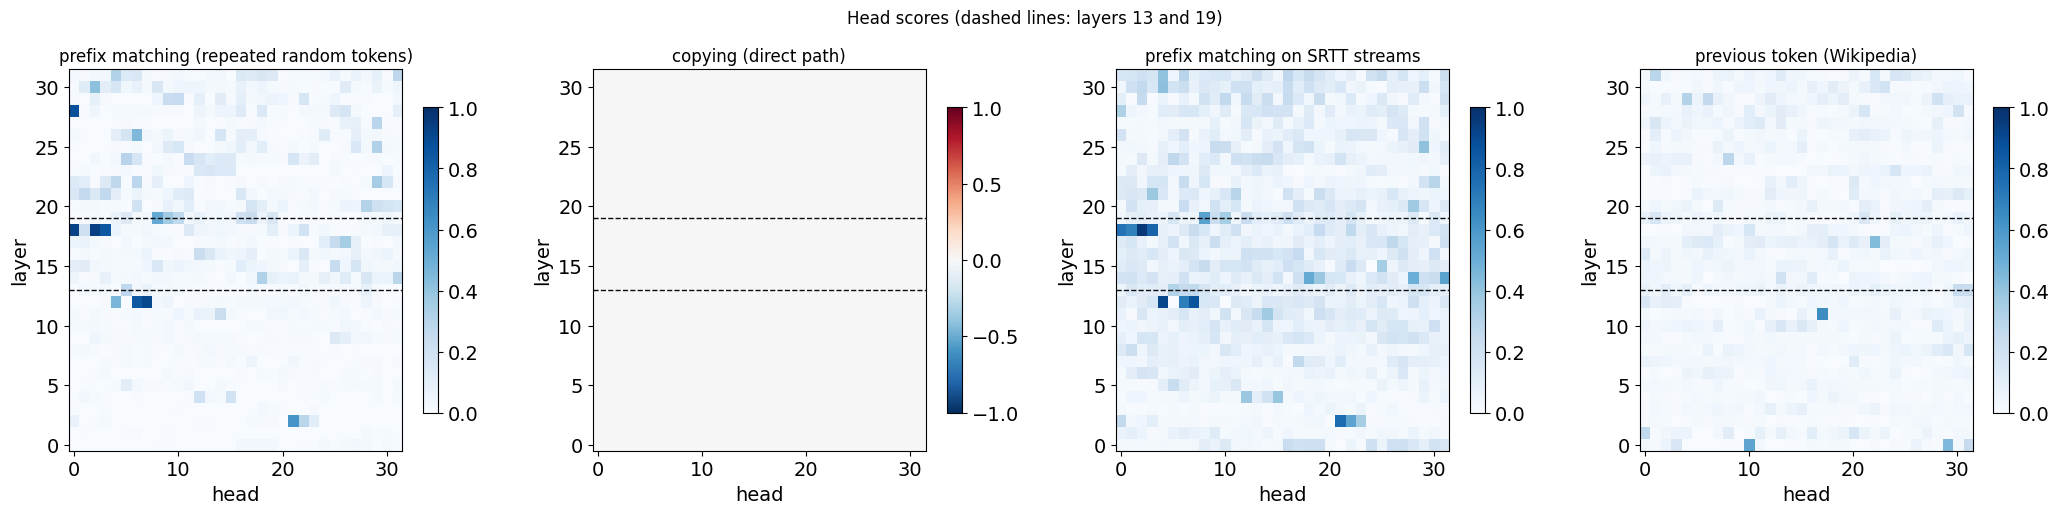

,layer,head,prefix,copying,prefix on SRTT,previous token,induction (both thresholds)
rank,,,,,,,
1,18,0,0.932,0.000,0.743,0.001,False
2,30,2,0.416,0.001,0.260,0.005,False
3,22,4,0.271,0.001,0.169,0.004,False
4,18,3,0.851,0.000,0.798,0.002,False
5,26,6,0.452,0.000,0.181,0.006,False
6,21,1,0.252,0.001,0.151,0.005,False
7,18,2,0.934,0.000,0.969,0.004,False
8,29,22,0.160,0.001,0.135,0.007,False
9,29,10,0.247,0.001,0.259,0.007,False


correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = 0.78


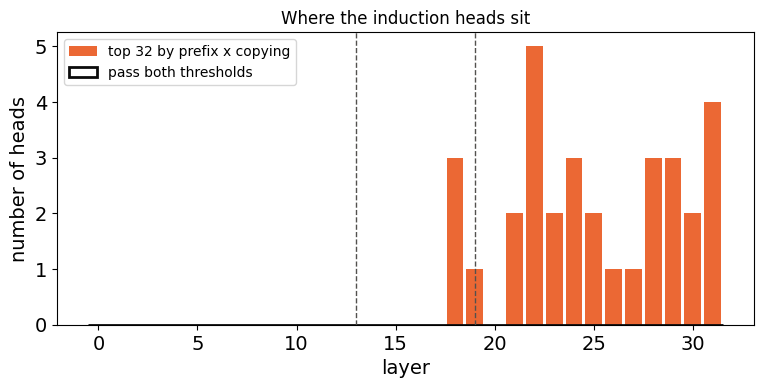

In [35]:
induction_rank_score = prefix_scores * np.clip(copy_scores, 0, None)
order = np.argsort(-induction_rank_score, axis=None)
ranked_heads = [tuple(int(v) for v in np.unravel_index(i, induction_rank_score.shape)) for i in order]
is_induction = (prefix_scores >= PREFIX_THRESHOLD) & (copy_scores >= COPY_THRESHOLD)
print(f"{int(is_induction.sum())} heads pass both thresholds (prefix >= {PREFIX_THRESHOLD}, copying >= {COPY_THRESHOLD})")


def plot_head_heatmaps(panels, title):
  fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.2), squeeze=False)
  for ax, (name, values, vmin, vmax, cmap) in zip(axes[0], panels):
    im = ax.imshow(values, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    for layer in (13, 19):
      if layer < NUM_LAYERS:
        ax.axhline(layer, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("head")
    ax.set_ylabel("layer")
    fig.colorbar(im, ax=ax, shrink=0.8)
  fig.suptitle(title)
  fig.tight_layout()
  plt.show()


plot_head_heatmaps([("prefix matching (repeated random tokens)", prefix_scores, 0, 1, 'Blues'),
                    ("copying (direct path)", copy_scores, -1, 1, 'RdBu_r'),
                    ("prefix matching on SRTT streams", srtt_prefix_scores, 0, 1, 'Blues'),
                    ("previous token (Wikipedia)", prev_token_scores, 0, 1, 'Blues')],
                   "Head scores (dashed lines: layers 13 and 19)")

top30 = pd.DataFrame([{"rank": r + 1, "layer": l, "head": h,
                       "prefix": prefix_scores[l, h], "copying": copy_scores[l, h],
                       "prefix on SRTT": srtt_prefix_scores[l, h], "previous token": prev_token_scores[l, h],
                       "induction (both thresholds)": bool(is_induction[l, h])}
                      for r, (l, h) in enumerate(ranked_heads[:30])]).set_index("rank")
display(top30.round(3))

corr = np.corrcoef(prefix_scores.ravel(), srtt_prefix_scores.ravel())[0, 1]
print(f"correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
layers_top = [l for l, _ in ranked_heads[:max(K_LIST)]]
ax.hist(layers_top, bins=np.arange(NUM_LAYERS + 1) - 0.5, color='#eb6834', rwidth=0.85,
        label=f"top {max(K_LIST)} by prefix x copying")
ax.hist(np.nonzero(is_induction)[0], bins=np.arange(NUM_LAYERS + 1) - 0.5, histtype='step', color='#0b0b0b',
        linewidth=2, label="pass both thresholds")
for layer in (13, 19):
  ax.axvline(layer, color='#52514e', linestyle='--', linewidth=1)
ax.set_xlabel("layer")
ax.set_ylabel("number of heads")
ax.set_title("Where the induction heads sit")
ax.legend()
plt.show()

## Step 2: switch the heads off (ablation)

### In plain words
Each head writes a 128-number vector into the layer's output projection (`o_proj`). To switch a head off we
replace **only its 128 numbers**, right before `o_proj`, and leave the other 31 heads of that layer untouched.

- **Mean ablation** (main): replace the head's vector with its **average** over Wikipedia text. The head then
  carries no information about the current input, but the model still receives the kind of signal it is used to.
- **Zero ablation** (secondary check, largest k only): replace it with zeros. This is harsher and can damage the
  model more for reasons unrelated to the head's role.

**Conditions** (each on AGL and SRTT, final-layer output only, the same `N_RUNS` streams):
1. no ablation: the baseline, which must reproduce the earlier results;
2. the top-k induction heads, for k = 4, 8, 16, 32 (does the effect grow with k?);
3. **random control**: k random non-induction heads with the **same number per layer** as the top-k set,
   3 different draws at the largest k. If these hurt as much, the effect is not specific to induction heads;
4. optional: the top-k previous-token heads.

The baseline and the largest induction ablation also get the full per-layer logit lens.

**Sanity checks** printed below: ablating one head changes exactly that head's 128 numbers in its layer's `o_proj`
input and nothing else, and every random draw has the same per-layer counts as the induction set.

In [36]:
def head_slice(h):
  return slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)


@contextmanager
def ablate_heads(model, heads, mode="mean", means=None):
  """Replaces the o_proj input slice of every (layer, head) in heads with its mean (or zero). Other heads untouched."""
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  handles = []
  for l, hs in by_layer.items():
    idx = torch.cat([torch.arange(h * HEAD_DIM, (h + 1) * HEAD_DIM) for h in hs])
    replacement = None if mode == "zero" else means[l][idx]

    def pre_hook(module, args, idx=idx, replacement=replacement):
      x = args[0].clone()
      idx_d = idx.to(x.device)
      x[..., idx_d] = 0 if replacement is None else replacement.to(device=x.device, dtype=x.dtype)
      return (x,) + tuple(args[1:])

    handles.append(model.model.layers[l].self_attn.o_proj.register_forward_pre_hook(pre_hook))
  try:
    yield
  finally:
    for handle in handles:
      handle.remove()


def compute_head_means():
  """Mean o_proj input per layer over Wikipedia text (train split; BOS position excluded)."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, MEAN_ABLATION_SEQS, TUNED_LENS_SEQ_LEN, "train")
  sums = torch.zeros(NUM_LAYERS, NUM_HEADS * HEAD_DIM, dtype=torch.float64)
  count = 0
  with torch.no_grad(), capture_heads(model, attention=False) as store:
    for start in range(0, len(tokens), WIKI_BATCH):
      model(input_ids=tokens[start:start + WIKI_BATCH].to(device), use_cache=False)
      for l in range(NUM_LAYERS):
        sums[l] += store["z"][l][:, 1:].double().sum(dim=(0, 1)).cpu()
      count += store["z"][0][:, 1:].shape[0] * store["z"][0][:, 1:].shape[1]
  return (sums / count).float().numpy()


head_means = torch.tensor(load_or_compute("head_means", compute_head_means))

# Sanity check: ablating one head changes only that head's slice of its layer's o_proj input.
check_layer, check_head = ranked_heads[0]
probe = load_lens_training_tokens(tokenizer, 1, 32, "validation").to(get_device())
with torch.no_grad():
  with capture_heads(model, attention=False) as clean:
    clean_logits = model(input_ids=probe, use_cache=False).logits.float()
  with ablate_heads(model, [(check_layer, check_head)], "mean", head_means), capture_heads(model, attention=False) as ablated:
    ablated_logits = model(input_ids=probe, use_cache=False).logits.float()
z_clean, z_abl = clean["z"][check_layer][0].float(), ablated["z"][check_layer][0].float()
inside = head_slice(check_head)
outside = torch.ones(z_clean.shape[-1], dtype=torch.bool)
outside[inside] = False
assert torch.allclose(z_clean[:, outside], z_abl[:, outside], atol=1e-3), "other heads in the layer changed"
assert torch.allclose(z_abl[:, inside], head_means[check_layer][inside].to(z_abl).expand_as(z_abl[:, inside]), atol=1e-2)
assert all(torch.allclose(clean["z"][l].float(), ablated["z"][l].float(), atol=1e-3) for l in range(check_layer)), "earlier layers changed"
print(f"[sanity] ablating layer {check_layer} head {check_head}: only its {HEAD_DIM} numbers changed in that layer; "
      f"output logits moved by up to {(clean_logits - ablated_logits).abs().max().item():.3f}")
del clean, ablated, clean_logits, ablated_logits

computed head_means in 62 s
[sanity] ablating layer 18 head 0: only its 128 numbers changed in that layer; output logits moved by up to 1.172


In [37]:
K_MAX = max(K_LIST)
induction_sets = {k: ranked_heads[:k] for k in K_LIST}
excluded = set(ranked_heads[:K_MAX]) | {(int(l), int(h)) for l, h in zip(*np.nonzero(is_induction))}


def layer_matched_random_heads(reference, seed):
  """Random non-induction heads with the same number per layer as `reference`."""
  rng = np.random.default_rng(seed)
  per_layer = defaultdict(int)
  for l, _ in reference:
    per_layer[l] += 1
  chosen = []
  for l, n in sorted(per_layer.items()):
    pool = [h for h in range(NUM_HEADS) if (l, h) not in excluded]
    assert len(pool) >= n, f"layer {l}: only {len(pool)} non-induction heads for {n} needed"
    chosen += [(l, int(h)) for h in rng.choice(pool, size=n, replace=False)]
  return chosen


def per_layer_counts(heads):
  counts = defaultdict(int)
  for l, _ in heads:
    counts[l] += 1
  return dict(counts)


conditions = {"baseline": {"heads": [], "mode": "mean", "lens": True}}
for k in K_LIST:
  conditions[f"induction_top{k}"] = {"heads": induction_sets[k], "mode": "mean", "lens": k == K_MAX}
for d in range(N_RANDOM_DRAWS):
  heads = layer_matched_random_heads(induction_sets[K_MAX], seed=d)
  assert per_layer_counts(heads) == per_layer_counts(induction_sets[K_MAX])
  conditions[f"random{K_MAX}_draw{d}"] = {"heads": heads, "mode": "mean", "lens": False}
if RUN_ZERO_ABLATION:
  conditions[f"induction_top{K_MAX}_zero"] = {"heads": induction_sets[K_MAX], "mode": "zero", "lens": False}
if RUN_PREV_TOKEN_CONDITION:
  prev_order = np.argsort(-prev_token_scores, axis=None)
  prev_heads = [tuple(int(v) for v in np.unravel_index(i, prev_token_scores.shape)) for i in prev_order[:K_MAX]]
  conditions[f"prevtoken_top{K_MAX}"] = {"heads": prev_heads, "mode": "mean", "lens": False}

print(f"[sanity] random draws match the induction set's per-layer counts: {per_layer_counts(induction_sets[K_MAX])}")
print(pd.DataFrame([{"condition": name, "heads ablated": len(c["heads"]), "mode": c["mode"],
                     "per-layer lens": c["lens"]} for name, c in conditions.items()]).set_index("condition"))

[sanity] random draws match the induction set's per-layer counts: {18: 3, 30: 2, 22: 5, 26: 1, 21: 2, 29: 3, 28: 3, 25: 2, 23: 2, 27: 1, 24: 3, 31: 4, 19: 1}
                      heads ablated  mode  per-layer lens
condition                                                
baseline                          0  mean            True
induction_top4                    4  mean           False
induction_top8                    8  mean           False
induction_top16                  16  mean           False
induction_top32                  32  mean            True
random32_draw0                   32  mean           False
random32_draw1                   32  mean           False
random32_draw2                   32  mean           False
induction_top32_zero             32  zero           False


### Runtime estimate
One AGL run is timed (final-layer pass); everything else is extrapolated from it. Conditions that are already
saved on Drive are not counted.

In [38]:
def condition_tag(name, cond):
  digest = hashlib.md5(f"{sorted(cond['heads'])}|{cond['mode']}".encode()).hexdigest()[:8]
  return f"{name}_{digest}"


def condition_cache_name(name, cond, grammar):
  return f"induction_heads/{lens_cache_name(grammar)}_{condition_tag(name, cond)}_{'lens' if cond['lens'] else 'final'}"


def is_cached(cache_name):
  return bool(LENS_CACHE_DIR) and os.path.exists(os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl"))


probe_inputs = prepare_lens_inputs(tokenizer, agl_prompts[0])
started = time.time()
extract_lens_logprobs(model, probe_inputs, [NUM_LAYERS])
seconds_per_run = time.time() - started
LENS_FACTOR = 2.5  # all-layer lens pass vs final-layer pass (46 vs 18 min per 100 runs earlier)
wiki_seconds = seconds_per_run * WIKI_EVAL_SEQS * 512 / probe_inputs["input_ids"].shape[1]
total = 0.0
for name, cond in conditions.items():
  for grammar in ("agl", "srtt"):
    if not is_cached(condition_cache_name(name, cond, grammar)):
      total += seconds_per_run * N_RUNS * (LENS_FACTOR if cond["lens"] else 1) * (1.1 if grammar == "srtt" else 1)
  if not (INDUCTION_DIR and os.path.exists(os.path.join(INDUCTION_DIR, f"wiki_{lens_cache_name('wiki')}_{condition_tag(name, cond)}.pkl"))):
    total += wiki_seconds
print(f"{seconds_per_run:.1f} s per AGL run (final layer). Estimated time for the remaining conditions: "
      f"{total / 3600:.1f} h (saved to Drive as it goes)")

13.3 s per AGL run (final layer). Estimated time for the remaining conditions: 5.5 h (saved to Drive as it goes)


### Run all conditions
Each condition runs AGL, SRTT and the Wikipedia controls with its heads ablated, then saves the results. Finished
conditions load from Drive in seconds; a condition interrupted halfway resumes from its last 10-run save.

In [39]:
def wikipedia_controls(name, cond):
  """Mean next-token loss and Olsson's ICL score (loss at token 500 - loss at token 50) on held-out Wikipedia."""
  path = os.path.join(INDUCTION_DIR, f"wiki_{lens_cache_name('wiki')}_{condition_tag(name, cond)}.pkl") if INDUCTION_DIR else None
  if path and os.path.exists(path):
    with open(path, 'rb') as f:
      return pickle.load(f)
  device = get_device()
  tokens = wiki_eval_tokens
  losses = []
  with torch.no_grad(), ablate_heads(model, cond["heads"], cond["mode"], head_means):
    for start in range(0, len(tokens), WIKI_BATCH):
      batch = tokens[start:start + WIKI_BATCH].to(device)
      logprobs = torch.log_softmax(model(input_ids=batch, use_cache=False).logits.float(), dim=-1)
      losses.append(-logprobs[:, :-1].gather(-1, batch[:, 1:, None]).squeeze(-1).cpu())  # (B, T-1): loss for token t+1
  losses = torch.cat(losses).numpy()
  result = {"loss": losses.mean(axis=1), "icl": losses[:, 499] - losses[:, 49]}  # per sequence
  if path:
    with open(path + ".tmp", 'wb') as f:
      pickle.dump(result, f)
    os.replace(path + ".tmp", path)
  return result


wiki_eval_tokens = load_lens_training_tokens(tokenizer, WIKI_EVAL_SEQS, 512, "test")
results = {}
for name, cond in conditions.items():
  print(f"=== {name}: {len(cond['heads'])} heads, {cond['mode']} ablation")
  layers = 'all' if cond["lens"] else [NUM_LAYERS]
  with ablate_heads(model, cond["heads"], cond["mode"], head_means):
    agl = run_lens_extraction(model, tokenizer, agl_prompts, layers, cache_name=condition_cache_name(name, cond, "agl"))["logit"]
    srtt = run_lens_extraction(model, tokenizer, srtt_prompts, layers, cache_name=condition_cache_name(name, cond, "srtt"))["logit"]
  results[name] = {"AGL": agl, "SRTT": srtt, "wiki": wikipedia_controls(name, cond)}
print("all conditions done")

=== baseline: 0 heads, mean ablation


  0%|          | 0/50 [00:00<?, ?it/s]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 7.53e+00


100%|██████████| 50/50 [23:47<00:00, 28.55s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


...

max |lens(last layer) - outputs.logits| over runs: 0.00e+00


  2%|▏         | 1/50 [00:12<10:04, 12.34s/it]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 7.04e+00


100%|██████████| 50/50 [09:50<00:00, 11.81s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00
all conditions done


## Steps 3 and 4: results

### In plain words
- **Normalized learning** (as in the earlier notebooks, final layer): (mean probability of the correct next word
  over the last 1,000 grammar words − the same over the first random part) ÷ (the best possible − that baseline).
  1 = as good as an ideal learner, 0 = no learning.
- **Wikipedia loss**: how wrong the model is on ordinary text (lower = better). If an ablation raises it a lot, the
  model is broken in general, and a drop in grammar learning says nothing specific.
- **ICL score** (Olsson et al.): loss on the 500th token of a text minus loss on the 50th. Negative = the model
  gets better as it reads more of a text, i.e. in-context learning on natural language. Induction heads are known
  to drive this, so this score should move toward 0 when they are ablated.

The table below has all three for every condition; the plots follow.

In [40]:
CONDITION_COLORS = {"baseline": "#0b0b0b", "induction": "#eb6834", "random": "#2a78d6", "zero": "#eb6834", "prevtoken": "#6250d6"}
GRAMMAR_PROMPTS = {"AGL": agl_prompts, "SRTT": srtt_prompts}


def final_layer_curves(lens_results, renormalize=False):
  return [lens_next_token_probs(r, renormalize=renormalize)[-1:] for r in lens_results]  # (1, N) per run


def final_summary(name, grammar, renormalize=False):
  df = lens_phase_summary(final_layer_curves(results[name][grammar], renormalize), GRAMMAR_PROMPTS[grammar])
  return df.iloc[-1]


rows = []
for name in conditions:
  row = {"condition": name, "heads": len(conditions[name]["heads"])}
  for grammar in ("AGL", "SRTT"):
    s = final_summary(name, grammar)
    row[f"{grammar} learning"] = s["norm_structured"]
    row[f"{grammar} ± SE"] = s["norm_structured_se"]
  row["Wiki loss"] = results[name]["wiki"]["loss"].mean()
  row["ICL score"] = results[name]["wiki"]["icl"].mean()
  rows.append(row)
overview = pd.DataFrame(rows).set_index("condition")
display(overview.round(3))

# Sanity check: the baseline reproduces the earlier results (layer 32, candidates-only, 02_tuned_lens: ~0.79 / ~1.0)
for grammar, expected in (("AGL", 0.79), ("SRTT", 1.0)):
  value = final_summary("baseline", grammar, renormalize=True)["norm_structured"]
  flag = "OK" if abs(value - expected) < 0.1 else "CHECK: differs from the earlier runs"
  print(f"[sanity] baseline {grammar}, layer 32 candidates-only normalized learning = {value:.3f} "
        f"(earlier: ~{expected}) -> {flag}")

,heads,AGL learning,AGL ± SE,SRTT learning,SRTT ± SE,Wiki loss,ICL score
condition,,,,,,,
baseline,0,0.745,0.008,0.997,0.000,2.051,-0.467
induction_top4,4,0.669,0.011,0.992,0.003,2.051,-0.468
induction_top8,8,0.592,0.013,0.984,0.005,2.054,-0.469
induction_top16,16,0.597,0.017,0.976,0.006,2.058,-0.482
induction_top32,32,0.405,0.027,0.872,0.015,2.079,-0.474
random32_draw0,32,0.743,0.009,0.997,0.000,2.060,-0.478
random32_draw1,32,0.740,0.008,0.996,0.000,2.062,-0.467
random32_draw2,32,0.728,0.009,0.996,0.000,2.065,-0.452
induction_top32_zero,32,0.407,0.027,0.879,0.014,2.081,-0.475


[sanity] baseline AGL, layer 32 candidates-only normalized learning = 0.794 (earlier: ~0.79) -> OK
[sanity] baseline SRTT, layer 32 candidates-only normalized learning = 0.998 (earlier: ~1.0) -> OK


### Learning curves (final layer)
Same as the paper's Fig. 3: probability of the correct next word at every position, averaged over runs and
smoothed over one sequence length. Black = no ablation, orange = the top induction heads ablated, blue = the same
number of random heads from the same layers. Dashed vertical lines = start and end of the grammar phase; the
dotted horizontal line = the best possible score.

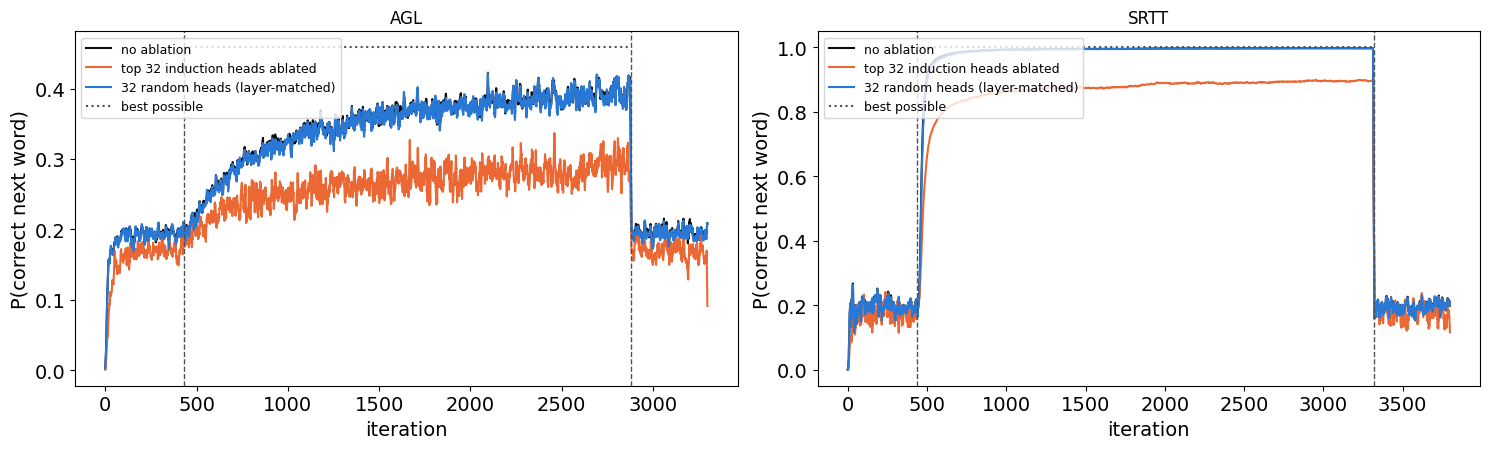

In [41]:
def plot_learning_curves(names, labels, colors):
  fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
  for ax, grammar, window in zip(axes, ("AGL", "SRTT"), (7, 9)):
    prompts = GRAMMAR_PROMPTS[grammar]
    for name, label, color in zip(names, labels, colors):
      aligned, (struct_start, struct_end) = align_runs(final_layer_curves(results[name][grammar]), prompts)
      mean = uniform_filter1d(aligned[:, 0].mean(axis=0), size=window, mode='nearest')
      ax.plot(mean, color=color, linewidth=1.5, label=label)
    gold, _ = align_runs([gold_next_token_probs(p)[None] for p in prompts], prompts)
    ax.hlines(gold[:, 0, struct_start:struct_end].mean(), struct_start, struct_end, color='#52514e', linestyle=':',
              label='best possible')
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#52514e', linestyle='--', linewidth=1)
    ax.set_title(grammar)
    ax.set_xlabel("iteration")
    ax.set_ylabel("P(correct next word)")
    ax.legend(fontsize=9, loc='upper left')
  fig.tight_layout()
  plt.show()


plot_learning_curves(["baseline", f"induction_top{K_MAX}", f"random{K_MAX}_draw0"],
                     ["no ablation", f"top {K_MAX} induction heads ablated", f"{K_MAX} random heads (layer-matched)"],
                     [CONDITION_COLORS["baseline"], CONDITION_COLORS["induction"], CONDITION_COLORS["random"]])

### Dose-response: learning and general ability vs. number of ablated heads
x-axis = number of heads ablated (0 = baseline). Orange line = top-k induction heads (mean ablation), with ±1 SE
across runs (grammar panels) or across Wikipedia sequences (right two panels). Blue points = the three random
layer-matched draws at the largest k, with their mean ± SE across draws. Open orange circle = zero ablation of the
same top-k set.

**Reading it:** a specific effect shows as the orange line falling while the blue points stay near the baseline,
and the Wikipedia loss staying roughly flat.

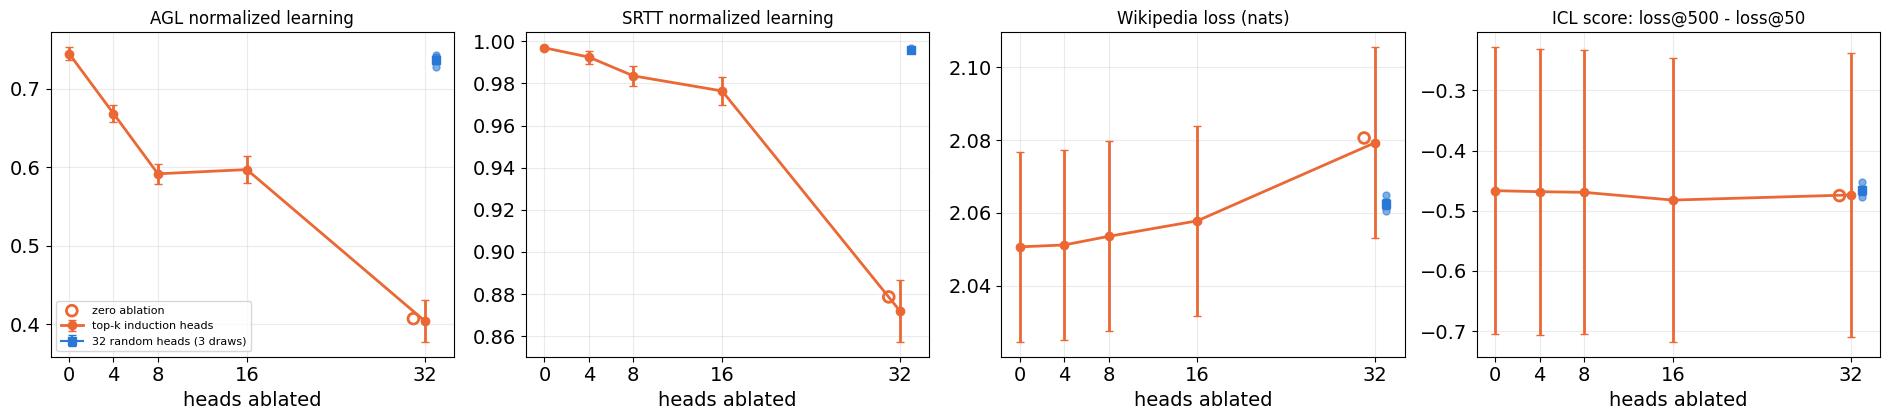

In [42]:
def metric_values(name, metric):
  if metric in ("AGL", "SRTT"):
    s = final_summary(name, metric)
    return s["norm_structured"], s["norm_structured_se"]
  values = results[name]["wiki"]["loss" if metric == "Wiki loss" else "icl"]
  return values.mean(), values.std(ddof=1) / np.sqrt(len(values))


metrics = [("AGL", "AGL normalized learning"), ("SRTT", "SRTT normalized learning"),
           ("Wiki loss", "Wikipedia loss (nats)"), ("ICL", "ICL score: loss@500 - loss@50")]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, (metric, title) in zip(axes, metrics):
  ks = [0] + K_LIST
  vals = [metric_values("baseline" if k == 0 else f"induction_top{k}", metric) for k in ks]
  ax.errorbar(ks, [v for v, _ in vals], yerr=[e for _, e in vals], color=CONDITION_COLORS["induction"], marker='o',
              linewidth=2, capsize=3, label="top-k induction heads")
  draws = [metric_values(f"random{K_MAX}_draw{d}", metric)[0] for d in range(N_RANDOM_DRAWS)]
  ax.scatter([K_MAX + 1.0] * len(draws), draws, color=CONDITION_COLORS["random"], s=25, alpha=0.6)
  ax.errorbar([K_MAX + 1.0], [np.mean(draws)], yerr=[np.std(draws, ddof=1) / np.sqrt(len(draws)) if len(draws) > 1 else 0],
              color=CONDITION_COLORS["random"], marker='s', capsize=3, label=f"{K_MAX} random heads (3 draws)")
  if RUN_ZERO_ABLATION:
    ax.scatter([K_MAX - 1.0], [metric_values(f"induction_top{K_MAX}_zero", metric)[0]], facecolors='none',
               edgecolors=CONDITION_COLORS["zero"], s=60, linewidths=2, label="zero ablation")
  if RUN_PREV_TOKEN_CONDITION:
    ax.scatter([K_MAX + 2.0], [metric_values(f"prevtoken_top{K_MAX}", metric)[0]], color=CONDITION_COLORS["prevtoken"],
               marker='^', s=50, label=f"top {K_MAX} previous-token heads")
  ax.set_title(title)
  ax.set_xlabel("heads ablated")
  ax.set_xticks(ks)
  ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Per-state check (AGL, state q1)
At state q1 three continuations are allowed (true probability 1/3 each) and two are forbidden. Without ablation the
model learns to raise the allowed ones and push the forbidden ones toward 0. Solid = mean probability of an allowed
word, dashed = of a forbidden word, over successive visits to q1 (smoothed over 10 visits). If the ablation removes
the learning, the two lines stay together.

baseline: last 100 visits, allowed 0.298 vs forbidden 0.030
induction_top32: last 100 visits, allowed 0.258 vs forbidden 0.035
random32_draw0: last 100 visits, allowed 0.295 vs forbidden 0.031


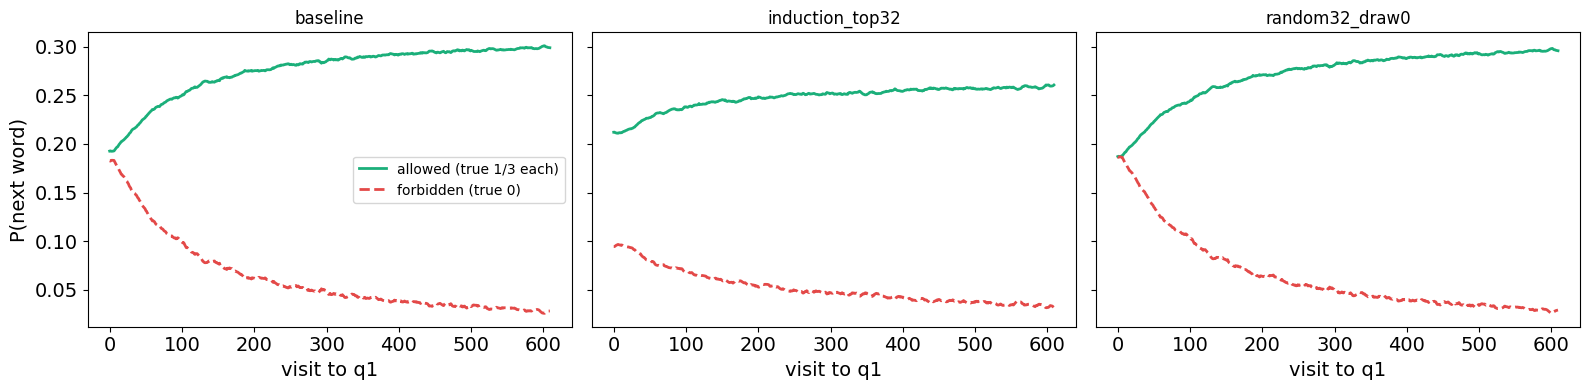

In [43]:
Q1_ALLOWED, Q1_FORBIDDEN = ["3", "0", "2"], ["1", SEP_TOKEN]


def q1_curves(name):
  allowed, forbidden = [], []
  for r, p in zip(results[name]["AGL"], agl_prompts):
    probs = np.exp(r["logprobs"][-1])  # (N, C) final layer, full vocabulary
    if probs.shape[1] != 5:
      continue  # two words share a first subword: columns do not map to symbols
    col = {s: (probs.shape[1] - 1 if s == SEP_TOKEN else int(s)) for s in Q1_ALLOWED + Q1_FORBIDDEN}
    lb = p["learning_begins"]
    q1 = [lb + i for i, state in enumerate(p["structure_state_sequences"]) if state == "q1"]
    allowed.append(probs[q1][:, [col[s] for s in Q1_ALLOWED]].mean(axis=1))
    forbidden.append(probs[q1][:, [col[s] for s in Q1_FORBIDDEN]].mean(axis=1))
  n = min(len(a) for a in allowed)
  return np.mean([a[:n] for a in allowed], axis=0), np.mean([f[:n] for f in forbidden], axis=0)


names = ["baseline", f"induction_top{K_MAX}", f"random{K_MAX}_draw0"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, name in zip(axes, names):
  allowed, forbidden = q1_curves(name)
  ax.plot(uniform_filter1d(allowed, 10, mode='nearest'), color='#1baf7a', linewidth=2, label="allowed (true 1/3 each)")
  ax.plot(uniform_filter1d(forbidden, 10, mode='nearest'), color='#e34948', linewidth=2, linestyle='--', label="forbidden (true 0)")
  ax.set_title(name)
  ax.set_xlabel("visit to q1")
  print(f"{name}: last 100 visits, allowed {allowed[-100:].mean():.3f} vs forbidden {forbidden[-100:].mean():.3f}")
axes[0].set_ylabel("P(next word)")
axes[0].legend()
fig.tight_layout()
plt.show()

### Per-layer logit lens: baseline vs. the largest induction ablation
Same summary as in `01_logit_lens` (each layer's learning relative to its own baseline), for the two conditions
with full per-layer passes. Solid = no ablation, dashed = top-k induction heads ablated. Does the jump at layer 19
disappear, shrink, or move to a later layer?

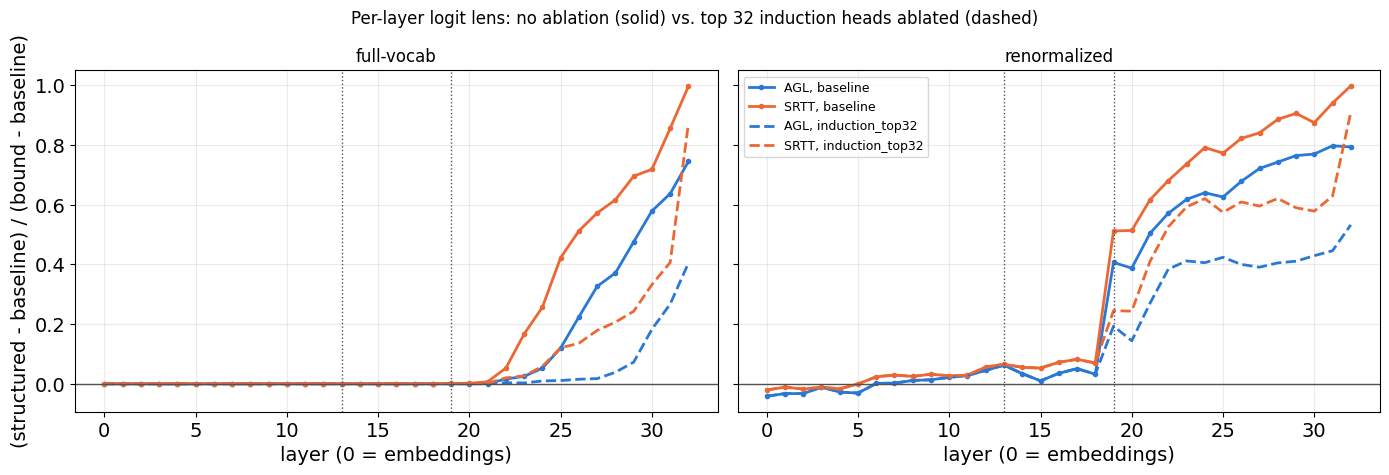

baseline        induction_top32  \
                                                 AGL   SRTT             AGL   
layer (candidates-only normalized learning)                                   
0                                             -0.042 -0.021          -0.042   
1                                             -0.033 -0.011          -0.033   
2                                             -0.033 -0.018          -0.033   
3                                             -0.011 -0.012          -0.011   
4                                             -0.028 -0.017          -0.028   
5                                             -0.031 -0.001          -0.031   
6                                              0.001  0.023           0.001   
7                                              0.002  0.029           0.002   
8                                              0.011  0.025           0.011   
9                                              0.013  0.032           0.013   
10                                             0.022  0.027           0.022   
11                                             0.028  0.029           0.028   
12                                             0.045  0.056           0.045   
13                                             0.062  0.065           0.062   
14                                             0.034  0.055           0.034   
15                                             0.010  0.053           0.010   
16                                             0.035  0.072           0.035   
17                                             0.051  0.082           0.051   
18                                             0.032  0.069           0.032   
19                                             0.406  0.512           0.193   
20                                             0.387  0.514           0.144   
21                                             0.504  0.616           0.270   
22                                             0.571  0.681           0.384   
23                                             0.618  0.736           0.412   
24                                             0.640  0.791           0.406   
25                                             0.626  0.773           0.424   
26                                             0.678  0.822           0.400   
27                                             0.721  0.841           0.390   
28                                             0.743  0.886           0.405   
29                                             0.764  0.906           0.411   
30                                             0.770  0.875           0.429   
31                                             0.797  0.940           0.446   
32                                             0.794  0.998           0.532   

                                                    
                                              SRTT  
layer (candidates-only normalized learning)         
0                                           -0.021  
1                                           -0.011  
2                                           -0.018  
3                                           -0.012  
4                                           -0.017  
5                                           -0.001  
6                                            0.023  
7                                            0.029  
8                                            0.025  
9                                            0.032  
10                                           0.027  
11                                           0.029  
12                                           0.056  
13                                           0.065  
14                                           0.055  
15                                           0.053  
16                                           0.072  
17                                           0.082  
18                                           0.069  
19                               

In [44]:
lens_condition_summaries = {}
for name in ("baseline", f"induction_top{K_MAX}"):
  lens_condition_summaries[name] = {
    grammar: {metric: lens_phase_summary([lens_next_token_probs(r, renormalize=(metric == "renormalized")) for r in results[name][grammar]],
                                         GRAMMAR_PROMPTS[grammar])
              for metric in ("full-vocab", "renormalized")}
    for grammar in ("AGL", "SRTT")}
layer_ids = results["baseline"]["AGL"][0]["layers"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, metric in zip(axes, ("full-vocab", "renormalized")):
  for name, style in (("baseline", "-"), (f"induction_top{K_MAX}", "--")):
    for grammar in ("AGL", "SRTT"):
      df = lens_condition_summaries[name][grammar][metric]
      ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=style, linewidth=2,
              marker='o' if style == "-" else None, markersize=3, label=f"{grammar}, {name}")
  for layer in (13, 19):
    ax.axvline(layer, color='#52514e', linestyle=':', linewidth=1)
  ax.axhline(0, color='#52514e', linewidth=1)
  ax.set_title(metric)
  ax.set_xlabel("layer (0 = embeddings)")
  ax.grid(alpha=0.25)
axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
axes[1].legend(fontsize=9)
fig.suptitle(f"Per-layer logit lens: no ablation (solid) vs. top {K_MAX} induction heads ablated (dashed)")
fig.tight_layout()
plt.show()

lens_table = pd.concat({(name, grammar): lens_condition_summaries[name][grammar]["renormalized"]["norm_structured"]
                        for name in lens_condition_summaries for grammar in ("AGL", "SRTT")}, axis=1)
lens_table.index = layer_ids
lens_table.index.name = "layer (candidates-only normalized learning)"
display(lens_table.round(3))

## How to interpret the results

Read the overview table and the dose-response plot together:

- **Both grammars collapse with induction-head ablation but not with random ablation, and the Wikipedia loss
  barely moves** → induction heads carry the in-context grammar learning.
- **SRTT collapses but AGL partly survives** → copying explains SRTT (a fixed sequence is pure *[A][B] … [A] → [B]*);
  AGL, where the next word is a probabilistic choice, also uses another mechanism.
- **Small effect for both** → backup heads take over, or other mechanisms carry the learning. Olsson et al. note
  that ablation evidence in large models with MLPs is only suggestive.
- **The Wikipedia loss rises a lot as well** → the ablation is too destructive to interpret; prefer fewer heads and
  mean ablation (compare with the zero-ablation point).
- **Random heads hurt about as much as induction heads** → the effect is not specific to induction heads.

The per-layer lens adds *where*: if the layer-19 jump disappears with the induction heads ablated, those heads are
what creates it; if it only shrinks or moves later, other components rebuild part of it.